# Gerando Slides para PowerPoint com a API do GPT-Image-2

Este notebook mostra, passo a passo, como **criar imagens de slides usando a API do GPT-Image-2** (via OpenRouter) e montar automaticamente um arquivo **.pptx** pronto para apresentação.

### Fluxo do tutorial
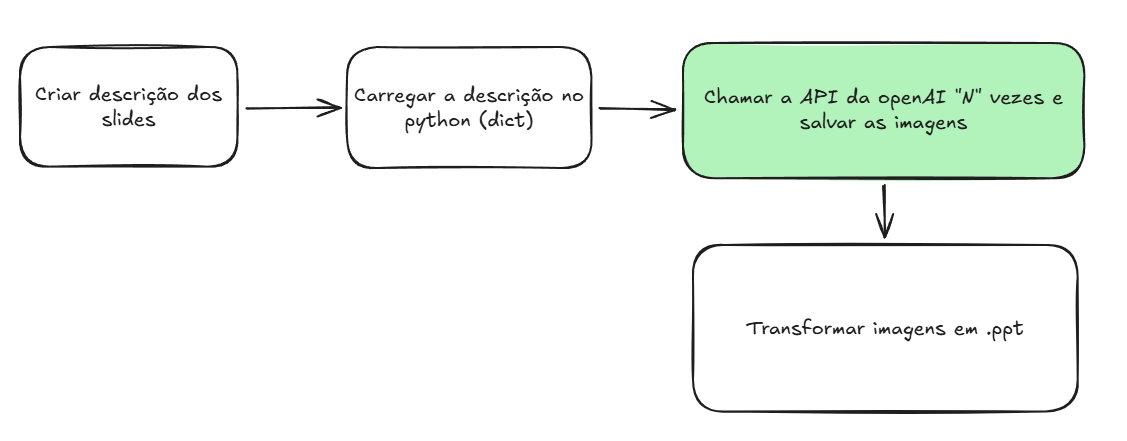
1. Carregar as descrições dos slides a partir de um arquivo **.md**
2. Gerar cada imagem de slide uma a uma (API GPT-Image-2) e salvar na pasta `imagens`
3. Ler as imagens da pasta e montar um **.pptx** com `python-pptx`

## 1. Instalação das dependências

Precisamos de:
- `requests` → chamadas HTTP à API
- `python-pptx` → criação do arquivo PowerPoint
- `python-dotenv` → (opcional) carregar a chave da API

In [ ]:
# Instala as bibliotecas necessárias (rode apenas uma vez)
!pip install requests python-pptx python-dotenv -q

## 2. Imports básicos

Importamos as bibliotecas que serão usadas em todo o notebook.

In [ ]:
import base64 #Codificador e decodificador de imagens: transformar os dados binários das imagens em texto (string)
import json
import mimetypes
from pathlib import Path
import os
import requests
from pptx import Presentation
from pptx.util import Inches
from dotenv import load_dotenv
import re

## 3. Configurações e chave da API

- A chave `OPENROUTER_API_KEY` fica guardada no arquivo `.env` (nunca exponha a chave no código).
- Definimos também os **caminhos** das pastas de entrada/saída e os parâmetros da API (modelo, qualidade, proporção).

> O modelo `openai/gpt-image-2` gera imagens em proporção 16:9, ideal para slides.

In [ ]:
# Carrega variáveis de ambiente do arquivo .env
load_dotenv('.env')

API_KEY = os.getenv('OPENROUTER_API_KEY')

# Pastas do projeto
PASTA_RAIZ    = Path('.').resolve()
ARQUIVO_MD    = PASTA_RAIZ / 'slides_descricao.md'   # descrições dos slides
PASTA_IMAGENS = PASTA_RAIZ / 'imagens'               # onde as imagens geradas serão salvas
ARQUIVO_PPTX  = PASTA_RAIZ / 'apresentacao.pptx'     # PowerPoint final

# Cria a pasta de imagens se não existir
PASTA_IMAGENS.mkdir(parents=True, exist_ok=True)

# Parâmetros da API do OpenRouter (Image API)
URL_API  = 'https://openrouter.ai/api/v1/images'
MODELO   = 'openai/gpt-image-2' #https://openrouter.ai/openai/gpt-image-2
QUALIDADE = 'high'      # 'low' | 'medium' | 'high'  (high melhora texto legível)
ASPECTO   = '16:9'      # proporção de tela para slides
TIMEOUT   = 300          # a geração pode demorar alguns minutos

print('Configuração carregada. Modelo:', MODELO)

## 4. Carregar a descrição dos slides (.md)

O arquivo `slides_descricao.md` deve conter uma seção por slide, separada por cabeçalhos `## Slide N` ou por linhas `---`.

Exemplo de formato:
```
## Slide 1
Título: Introdução ao Machine Learning
Crie um slide com fundo azul escuro, título centralizado em branco...

## Slide 2
Título: Algoritmos Supervisionados
...
```

In [ ]:
def carregar_descricoes(caminho_md: Path) -> list[dict]:
    """
    Lê o arquivo .md e retorna uma lista de slides no formato:
      [{'nome': 'slide_01', 'prompt': 'descrição completa'}, ...]

    Suporta dois formatos de separação:
      - Cabeçalhos Markdown:  ## Slide 1
      - Separador de linhas:  ---
    """
    texto = caminho_md.read_text(encoding='utf-8')

    # Tenta primeiro pelo padrão ## Slide N
    blocos = re.split(r'(?=^##\s+Slide\s+\d+)', texto, flags=re.MULTILINE)
    blocos = [b.strip() for b in blocos if b.strip()]

    slides = []
    for i, bloco in enumerate(blocos, start=1):
        # Extrai o título (primeira linha ##) e o restante como prompt
        linhas = bloco.splitlines()
        prompt = '\n'.join(linhas[1:]).strip() if linhas[0].startswith('##') else bloco
        nome = f'slide_{i:02d}'
        slides.append({'nome': nome, 'prompt': prompt})

    # Fallback: separar por --- caso não tenha encontrado cabeçalhos ##
    if not slides:
        partes = re.split(r'^---\s*$', texto, flags=re.MULTILINE)
        for i, parte in enumerate(partes, start=1):
            parte = parte.strip()
            if parte:
                slides.append({'nome': f'slide_{i:02d}', 'prompt': parte})

    if not slides:
        raise ValueError('Nenhum slide encontrado no arquivo .md')
    return slides

# Carrega e mostra um resumo
slides = carregar_descricoes(ARQUIVO_MD)
print(f'{len(slides)} slides carregados do arquivo {ARQUIVO_MD.name}:')
for s in slides:
    print(f"  - {s['nome']}: {s['prompt'][:60]}...")

In [ ]:
print(slides[2]['prompt'])

## 5. Função para gerar uma imagem via API GPT-Image-2

Esta função envia o **prompt** do slide para a Image API do OpenRouter e retorna os **bytes da imagem** gerada em PNG.

In [ ]:
def gerar_imagem(prompt: str) -> bytes:
    """
    Chama a Image API do OpenRouter (modelo gpt-image-2) e retorna
    os bytes de uma imagem PNG 16:9 gerada a partir do prompt.
    """
    payload = {
        'model': MODELO,
        'prompt': prompt,
        'aspect_ratio': ASPECTO,
        'quality': QUALIDADE,
    }

    resposta = requests.post(
        url=URL_API,
        headers={
            'Authorization': f'Bearer {API_KEY}',
            'Content-Type': 'application/json',
        },
        data=json.dumps(payload),
        timeout=TIMEOUT,
    )

    if not resposta.ok:
        raise RuntimeError(
            f'API retornou status {resposta.status_code}: {resposta.text[:300]}'
        )

    dados = resposta.json().get('data', [])
    if not dados:
        raise RuntimeError('A API não retornou nenhuma imagem')

    return base64.b64decode(dados[0]['b64_json'])

print('Função `gerar_imagem` definida.')

## 6. Gerar os slides um a um e salvar na pasta `imagens`

Percorremos a lista de descrições, geramos cada imagem e salvamos como `slide_01.png`, `slide_02.png`, etc.

**Dica de economia:** se a imagem já existe na pasta, pulamos a chamada à API (igual ao `revisor.py` faz com slides já revisados).

In [ ]:
for slide in slides:
    caminho_img = PASTA_IMAGENS / f"{slide['nome']}.png"

    # Pula imagens já geradas para evitar gasto repetido com a API
    if caminho_img.exists():
        print(f"Pulando (já existe): {caminho_img.name}")
        continue

    print(f"Gerando: {caminho_img.name} ...", end=' ', flush=True)
    try:
        bytes_img = gerar_imagem(slide['prompt'])
        caminho_img.write_bytes(bytes_img)
        print('OK.')
    except Exception as exc:
        print(f'ERRO: {exc}')

print(f"\nImagens salvas em: {PASTA_IMAGENS}")

## 7. Visualizar as imagens geradas

Antes de montar o PowerPoint, vale a pena conferir visualmente se as imagens ficaram boas.

In [ ]:
from IPython.display import display, Image

imagens = sorted(PASTA_IMAGENS.glob('*.png'))
for img in imagens:
    print(img.name)
    display(Image(filename=str(img)))

## 8. Montar o arquivo PowerPoint (.pptx)

Usamos `python-pptx` para:
1. Criar uma apresentação com tamanho 16:9 (13.333 x 7.5 polegadas)
2. Adicionar um slide em branco para cada imagem
3. Inserir cada imagem preenchendo toda a área do slide
4. Salvar como `apresentacao.pptx`

In [ ]:
# Lista as imagens em ordem (slide_01, slide_02, ...)
imagens = sorted(PASTA_IMAGENS.glob('*.png'))

# Cria a apresentação em 16:9
prs = Presentation()
prs.slide_width  = Inches(13.333)
prs.slide_height = Inches(7.5)

blank_layout = prs.slide_layouts[6]  # layout em branco

for img in imagens:
    slide = prs.slides.add_slide(blank_layout)
    # Insere a imagem ocupando todo o slide
    slide.shapes.add_picture(
        str(img),
        left=0,
        top=0,
        width=prs.slide_width,
        height=prs.slide_height,
    )
    print(f'Slide adicionado: {img.name}')

prs.save(str(ARQUIVO_PPTX))
print(f'\nPowerPoint salvo em: {ARQUIVO_PPTX}')
print(f'Total de slides: {len(prs.slides)}')